# Part 2 analysis: dataset description and failure modes (Poushali)

Team 16, DATA 266 Lab 2. CPU notebook. It describes the Naruto dataset (Task 2.1) and studies the failure modes of the team's two LoRA runs (Task 2.4), using the 120 images the team notebook `p2_finetune_team16.ipynb` uploaded to Hugging Face (`sadaffatimaeee/naruto-lora-generations`).

In [1]:
import os, subprocess
REPO = "github.com/sadaffatimaee/data266-lab2-team16.git"
if subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True).returncode != 0 and os.path.isdir("/kaggle"):
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("GITHUB_TOKEN")
        subprocess.run(["git", "clone", "-q", f"https://{token}@{REPO}", "/tmp/repo"], check=True)
        subprocess.run(["git", "-C", "/tmp/repo", "remote", "set-url", "origin", f"https://{REPO}"], check=True)
        os.chdir("/tmp/repo")
    except Exception as e:
        print("repository not cloned:", type(e).__name__)
ROOT = subprocess.run(["git", "rev-parse", "--show-toplevel"], capture_output=True, text=True).stdout.strip()

import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
text=True).stdout.strip()
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
"gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

{'commit': 'bff4557', 'python': '3.12.10', 'torch': '2.14.0+cpu', 'gpu': 'cpu', 'seed': 266}


In [2]:
import io, os, json, hashlib
import pandas as pd
from PIL import Image
from datasets import load_dataset, Image as HFImage
from huggingface_hub import snapshot_download
import matplotlib.pyplot as plt

raw = load_dataset("lambdalabs/naruto-blip-captions", split="train").cast_column("image", HFImage(decode=False))
sizes, caps = [], []
for r in raw:
    im = Image.open(io.BytesIO(r["image"]["bytes"]))
    sizes.append(im.size)
    caps.append(str(r["text"]).strip())
sz = pd.Series([f"{w}x{h}" for w, h in sizes])
words = pd.Series(" ".join(caps).lower().replace(",", " ").split())
lens = pd.Series([len(c.split()) for c in caps])
print("images:", len(caps), "| distinct sizes:", sz.nunique(), "| most common:", sz.value_counts().head(3).to_dict())
print("caption length in words: mean", round(lens.mean(), 1), "| min", lens.min(), "| max", lens.max())
print("distinct captions:", len(set(caps)), "of", len(caps))
print("most repeated captions:", pd.Series(caps).value_counts().head(5).to_dict())
groups = {"male words (man, boy, he, his)": ["man", "boy", "he", "his", "men"],
          "female words (woman, girl, she, her)": ["woman", "girl", "she", "her", "women"]}
for g, ws in groups.items():
    print(g, "->", sum(any(w in c.lower().split() for w in ws) for c in caps), "captions")
anime_words = ["anime", "cartoon", "naruto", "ninja", "drawing"]
print("captions naming a style or the domain (anime, cartoon, naruto, ninja, drawing):",
      sum(any(w in c.lower() for w in anime_words) for c in caps))
print("top 20 words:", words[~words.isin(["a", "with", "and", "in", "of", "the", "on", "an"])].value_counts().head(20).to_dict())

Repo card metadata block was not found. Setting CardData to empty.


images: 1221 | distinct sizes: 358 | most common: {'1080x1080': 468, '1076x1076': 135, '1620x1620': 33}
caption length in words: mean 8.9 | min 6 | max 41
distinct captions: 967 of 1221
most repeated captions: {'a man with a sword in his hand': 35, 'a man with a gun in his hand': 12, 'two people standing next to each other people': 9, 'a man with a baseball cap on his head': 8, 'a woman with a sword in her hand': 7}
male words (man, boy, he, his) -> 727 captions
female words (woman, girl, she, her) -> 248 captions
captions naming a style or the domain (anime, cartoon, naruto, ninja, drawing): 54
top 20 words: {'man': 692, 'hair': 465, 'shirt': 193, 'white': 192, 'eyes': 181, 'long': 181, 'black': 180, 'woman': 175, 'his': 163, 'green': 142, 'blue': 137, 'hat': 126, 'red': 115, 'brown': 95, 'sword': 86, 'person': 83, 'hand': 83, 'hoodie': 79, 'jacket': 76, 'standing': 75}


## Failure modes of the team runs
The images are the team's generations: base model, run 1 (LoRA rank 4) and run 2 (LoRA rank 16, the final run), 20 prompts x seeds 0 and 1.

In [3]:
root = snapshot_download("sadaffatimaeee/naruto-lora-generations", repo_type="dataset")
meta = pd.read_csv(f"{root}/metadata.csv")
MODELS = ["base", "run1_lora_r4", "run2_lora_r16"]
meta["path"] = root + "/" + meta["file_name"]
meta["black"] = [np.asarray(Image.open(p).convert("L")).max() < 10 for p in meta["path"]]
print("black (blocked) images per model:", meta.groupby("model")["black"].sum().to_dict())
print(meta[meta["black"]][["model", "pid", "seed", "prompt", "nsfw_flagged"]].to_string(index=False))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 123 files:   0%|          | 0/123 [00:00<?, ?it/s]

black (blocked) images per model: {'base': 0, 'run1_lora_r4': 1, 'run2_lora_r16': 1}
        model pid  seed                             prompt  nsfw_flagged
 run1_lora_r4 P02     1 a man with red hair and green eyes          True
run2_lora_r16 P09     1 a man with sunglasses and a hat on          True


### Failure 1: the domain style is not applied to out-of-domain prompts
A CLIP style score measures how much more an image looks like an anime drawing than a photograph: 100 x (cos(image, 'an anime drawing in the style of Naruto') - cos(image, 'a photograph')). Blocked black images are left out.

In [4]:
from transformers import CLIPModel, CLIPProcessor
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch16").eval()
cproc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch16")

@torch.no_grad()
def emb_img(paths):
    out = []
    for i in range(0, len(paths), 16):
        px = cproc(images=[Image.open(p).convert("RGB") for p in paths[i:i + 16]], return_tensors="pt")["pixel_values"]
        e = clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output)
        out.append(e / e.norm(dim=-1, keepdim=True))
    return torch.cat(out)

@torch.no_grad()
def emb_txt(t):
    x = cproc(text=t, return_tensors="pt", padding=True)
    e = clip.text_projection(clip.text_model(input_ids=x["input_ids"], attention_mask=x["attention_mask"]).pooler_output)
    return e / e.norm(dim=-1, keepdim=True)

ok = meta[~meta["black"]].copy()
e = emb_img(list(ok["path"]))
t = emb_txt(["an anime drawing in the style of Naruto", "a photograph"])
ok["style_score"] = (100 * (e @ t[0] - e @ t[1])).numpy()
style = ok.pivot_table(index="type", columns="model", values="style_score", aggfunc="mean")[MODELS].round(2)
print("mean CLIP style score (higher = more anime-like)")
print(style.to_string())
print("RESULTS_JSON", json.dumps({"style_score": style.to_dict(), "black_images": meta.groupby("model")["black"].sum().astype(int).to_dict()}))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

mean CLIP style score (higher = more anime-like)
model          base  run1_lora_r4  run2_lora_r16
type                                            
compositional -7.64          3.34           4.19
in_domain     -8.05         -2.61           1.75
out_of_domain -9.55        -10.24         -10.28
RESULTS_JSON {"style_score": {"base": {"compositional": -7.639999866485596, "in_domain": -8.050000190734863, "out_of_domain": -9.550000190734863}, "run1_lora_r4": {"compositional": 3.3399999141693115, "in_domain": -2.609999895095825, "out_of_domain": -10.239999771118164}, "run2_lora_r16": {"compositional": 4.190000057220459, "in_domain": 1.75, "out_of_domain": -10.279999732971191}}, "black_images": {"base": 0, "run1_lora_r4": 1, "run2_lora_r16": 1}}


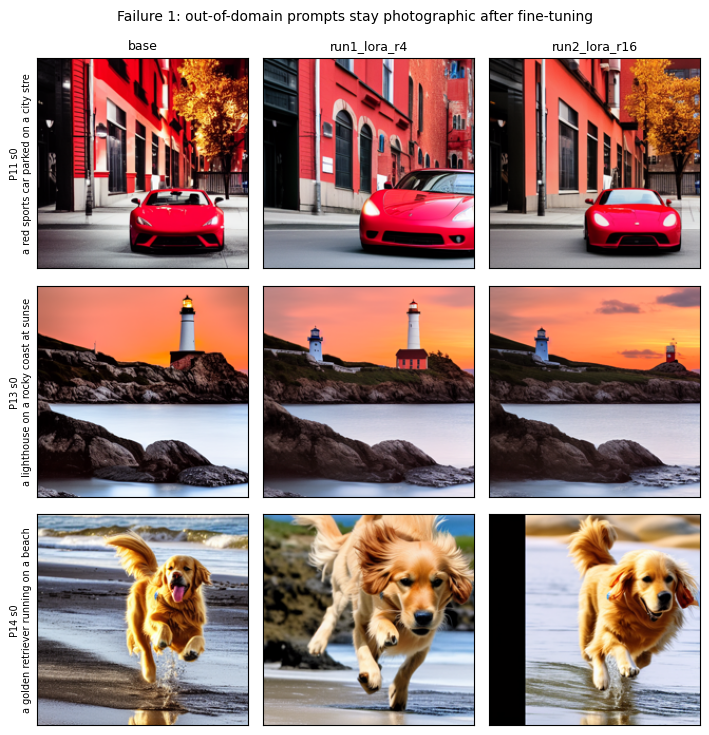

In [5]:
def grid(rows, title, fn, S=200):
    fig, ax = plt.subplots(len(rows), len(MODELS), figsize=(len(MODELS) * 2.4, len(rows) * 2.5))
    for i, (pid, seed) in enumerate(rows):
        for j, m in enumerate(MODELS):
            r = meta[(meta["model"] == m) & (meta["pid"] == pid) & (meta["seed"] == seed)].iloc[0]
            ax[i, j].imshow(Image.open(r["path"]).convert("RGB").resize((S, S)))
            ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
            if i == 0:
                ax[i, j].set_title(m, fontsize=9)
            if j == 0:
                ax[i, j].set_ylabel(f"{pid} s{seed}\n" + r["prompt"][:38], fontsize=7)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    os.makedirs("figures", exist_ok=True)
    plt.savefig(f"figures/{fn}", dpi=110)
    plt.show()

grid([("P11", 0), ("P13", 0), ("P14", 0)], "Failure 1: out-of-domain prompts stay photographic after fine-tuning", "p2_failure_out_of_domain.png")

### Failure 2: attributes are mixed up in compositional prompts
Prompts with two or three people and a colour for each are checked with CLIP: for each image, does it match the correct prompt better than a version with the colours swapped?

compositional images where CLIP prefers the correct colour binding over the swapped one
               sum  count
model                    
base             7      8
run1_lora_r4     5      8
run2_lora_r16    4      8
RESULTS_JSON {"binding_ok": {"base": [7, 8], "run1_lora_r4": [5, 8], "run2_lora_r16": [4, 8]}}


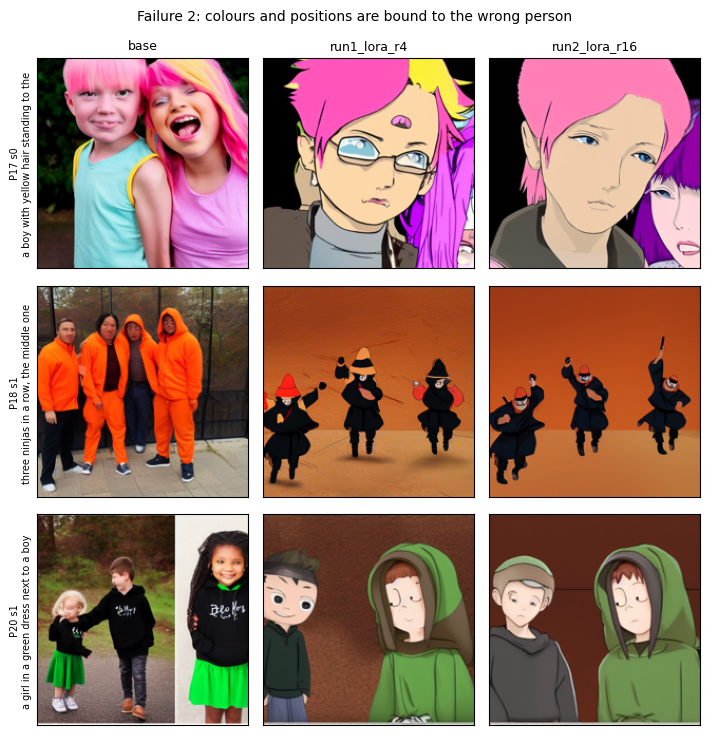

In [6]:
swaps = {"P17": "a boy with pink hair standing to the left of a girl with yellow hair",
         "P18": "three ninjas in a row, the middle one wearing a black jacket and the others orange",
         "P19": "a man with red hair holding a white umbrella in the rain",
         "P20": "a girl in a black dress next to a boy in a green hoodie"}
comp = ok[ok["pid"].isin(swaps)].copy()
ce = emb_img(list(comp["path"]))
right = emb_txt(list(comp["prompt"]))
wrong = emb_txt([swaps[p] for p in comp["pid"]])
comp["binding_ok"] = ((ce * right).sum(-1) > (ce * wrong).sum(-1)).numpy()
bind = comp.groupby("model")["binding_ok"].agg(["sum", "count"]).reindex(MODELS)
print("compositional images where CLIP prefers the correct colour binding over the swapped one")
print(bind.to_string())
print("RESULTS_JSON", json.dumps({"binding_ok": {m: [int(r["sum"]), int(r["count"])] for m, r in bind.iterrows()}}))
grid([("P17", 0), ("P18", 1), ("P20", 1)], "Failure 2: colours and positions are bound to the wrong person", "p2_failure_composition.png")

### Failure 3: the NSFW safety checker blocks harmless prompts
The pipeline's safety checker replaces a flagged image with a black square. All flagged prompts above are harmless (hair colour, sunglasses), so these are false positives that remove outputs from the evaluation.

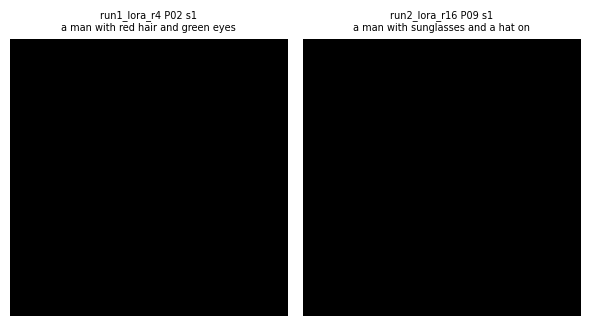

In [7]:
bl = meta[meta["black"]]
fig, ax = plt.subplots(1, max(len(bl), 1), figsize=(3 * max(len(bl), 1), 3.2), squeeze=False)
for k, (_, r) in enumerate(bl.iterrows()):
    ax[0, k].imshow(Image.open(r["path"]).convert("RGB")); ax[0, k].axis("off")
    ax[0, k].set_title(f"{r['model']} {r['pid']} s{r['seed']}\n{r['prompt'][:34]}", fontsize=7)
plt.tight_layout(); plt.savefig("figures/p2_failure_nsfw.png", dpi=110); plt.show()